# Chapitre 10 - Cours 1 : AdaBoost, modélisation additive pas à pas et perte exponentielle

Ce premier notebook couvre les sections 10.1 à 10.5 du livre :

1. l'idée du *boosting* et l'algorithme **AdaBoost.M1** (algorithme 10.1) ;
2. son efficacité spectaculaire sur la simulation des « sphères emboîtées » (éq. (10.2), figure 10.2) ;
3. la **modélisation additive pas à pas** (*forward stagewise*, algorithme 10.2) ;
4. l'équivalence entre AdaBoost et la modélisation pas à pas avec la **perte exponentielle** (éq. (10.8)–(10.15)) ;
5. ce que la perte exponentielle estime : la moitié du **log-rapport de cotes** (éq. (10.16)–(10.17)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl.ch10_boosting import AdaBoostM1, RegressionTree, simulate_nested_spheres

## 1. L'idée du boosting

On se place en **classification binaire** : la réponse est codée $Y \in \{-1, +1\}$ et un
classifieur est une fonction $G(x) \in \{-1,+1\}$. Son taux d'erreur sur l'échantillon
d'apprentissage $(x_i, y_i)_{1\le i\le N}$ est

$$\overline{\mathrm{err}} = \frac{1}{N}\sum_{i=1}^N I\big(y_i \neq G(x_i)\big),$$

où $I(\cdot)$ vaut 1 si la condition est vraie et 0 sinon.

Un **classifieur faible** est un classifieur à peine meilleur que le hasard (erreur
légèrement inférieure à $1/2$). Le boosting applique *séquentiellement* un même
algorithme faible à des versions **repondérées** des données, produisant des
classifieurs $G_1, \dots, G_M$, puis les combine par un **vote majoritaire pondéré** :

$$G(x) = \operatorname{signe}\Big(\sum_{m=1}^M \alpha_m G_m(x)\Big) \qquad \text{(éq. (10.1) du livre).}$$

> **Intuition.** À chaque étape, on augmente le poids des observations que le classifieur
> précédent a mal classées : le classifieur suivant est ainsi « forcé » de se concentrer
> sur les cas difficiles. Les coefficients $\alpha_m$ donnent plus d'influence aux
> classifieurs les plus précis.

### Algorithme 10.1 - AdaBoost.M1 (reformulé)

1. Initialiser les poids $w_i = 1/N$, $i = 1, \dots, N$.
2. Pour $m = 1, \dots, M$ :
   1. ajuster un classifieur $G_m$ aux données munies des poids $w_i$ ;
   2. calculer l'erreur pondérée $\displaystyle \mathrm{err}_m = \frac{\sum_i w_i\, I(y_i \ne G_m(x_i))}{\sum_i w_i}$ ;
   3. calculer $\alpha_m = \log\big((1-\mathrm{err}_m)/\mathrm{err}_m\big)$ ;
   4. mettre à jour $w_i \leftarrow w_i \exp\big[\alpha_m I(y_i \ne G_m(x_i))\big]$.
3. Renvoyer $G(x) = \operatorname{signe}\big(\sum_m \alpha_m G_m(x)\big)$.

Si $\mathrm{err}_m < 1/2$, alors $\alpha_m > 0$ et les observations mal classées voient
leur poids multiplié par $e^{\alpha_m} = (1-\mathrm{err}_m)/\mathrm{err}_m > 1$.

Le classifieur faible utilisé ici est une **souche** (*stump*) : un arbre de classification
à deux feuilles, qui coupe selon une seule variable $X_j \le s$. Dans notre module
`esl.ch10_boosting`, une souche pondérée est obtenue en ajustant un arbre de moindres carrés
pondérés à la cible $y \in\{-1,1\}$ puis en prenant le signe de chaque feuille (pour une
cible binaire, le critère des moindres carrés pondérés est l'indice de Gini pondéré).

## 2. La simulation des sphères emboîtées (éq. (10.2))

Les dix variables $X_1, \dots, X_{10}$ sont des gaussiennes centrées réduites indépendantes et

$$Y = \begin{cases} +1 & \text{si } \sum_{j=1}^{10} X_j^2 > \chi^2_{10}(0{,}5),\\ -1 & \text{sinon,}\end{cases}$$

où $\chi^2_{10}(0{,}5) \approx 9{,}34$ est la médiane d'une loi du khi-deux à 10 degrés de
liberté (loi de $\sum_j X_j^2$). Les deux classes sont donc équiprobables et la frontière
de Bayes est une sphère : l'erreur de Bayes est **nulle**. On tire 2000 observations
d'apprentissage et 10 000 de test, comme dans le livre.

In [2]:
rng = np.random.RandomState(0)
X, y = simulate_nested_spheres(2000, rng=rng)
Xt, yt = simulate_nested_spheres(10000, rng=rng)
print("proportion de la classe +1 (apprentissage) : %.3f" % np.mean(y == 1))

proportion de la classe +1 (apprentissage) : 0.490


Visualisons la variable qui détermine la classe, $R^2 = \sum_j X_j^2$. Aucune variable
**seule** ne sépare les classes : une souche, qui ne coupe que selon un $X_j$, sera donc
très faible.

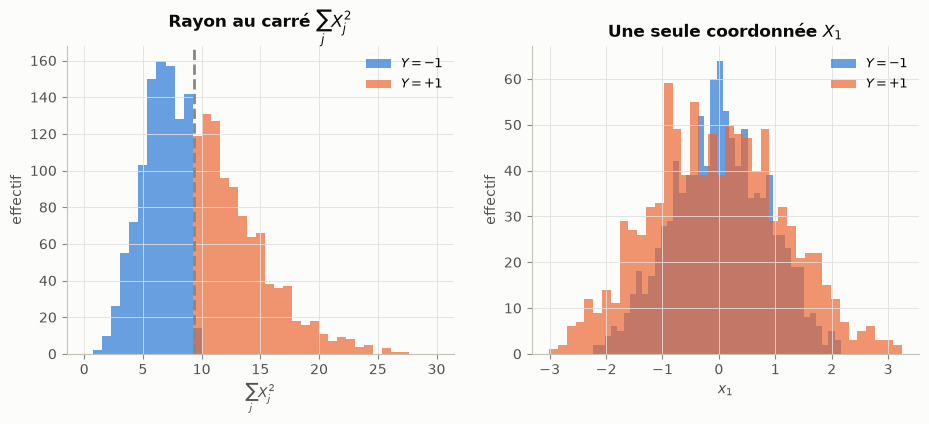

In [3]:
r2 = (X ** 2).sum(1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0, 30, 40)
axes[0].hist(r2[y == -1], bins, color=BLUE, alpha=0.7, label="$Y=-1$")
axes[0].hist(r2[y == 1], bins, color=ORANGE, alpha=0.7, label="$Y=+1$")
axes[0].axvline(9.34, color=GRAY, ls="--")
axes[0].set(title="Rayon au carré $\\sum_j X_j^2$", xlabel="$\\sum_j X_j^2$", ylabel="effectif")
axes[0].legend()
axes[1].hist(X[y == -1, 0], 40, color=BLUE, alpha=0.7, label="$Y=-1$")
axes[1].hist(X[y == 1, 0], 40, color=ORANGE, alpha=0.7, label="$Y=+1$")
axes[1].set(title="Une seule coordonnée $X_1$", xlabel="$x_1$", ylabel="effectif")
axes[1].legend()
plt.show()

### Deux références : une souche seule et un grand arbre

Le livre annonce une erreur de test de 45,8 % pour une souche seule et de 24,7 % pour
un arbre de classification à 244 nœuds terminaux.

In [4]:
stump = RegressionTree(n_leaves=2).fit(X, y)
err_stump = np.mean(np.where(stump.predict(Xt) >= 0, 1, -1) != yt)
big = RegressionTree(n_leaves=244).fit(X, y)
err_big = np.mean(np.where(big.predict(Xt) >= 0, 1, -1) != yt)
print("souche seule      : erreur de test = %.3f" % err_stump)
print("arbre à 244 nœuds : erreur de test = %.3f" % err_big)

souche seule      : erreur de test = 0.457
arbre à 244 nœuds : erreur de test = 0.259


### AdaBoost avec souches : figure 10.2

On lance 400 itérations d'AdaBoost.M1 et on suit l'erreur de test après chaque itération.

In [5]:
ada = AdaBoostM1(n_estimators=400, n_leaves=2).fit(X, y)
test_err = ada.staged_errors(Xt, yt)
train_err = ada.staged_errors(X, y)
print("erreur de test après 1, 100, 400 itérations : %.3f, %.3f, %.3f"
      % (test_err[0], test_err[99], test_err[-1]))

erreur de test après 1, 100, 400 itérations : 0.457, 0.200, 0.117


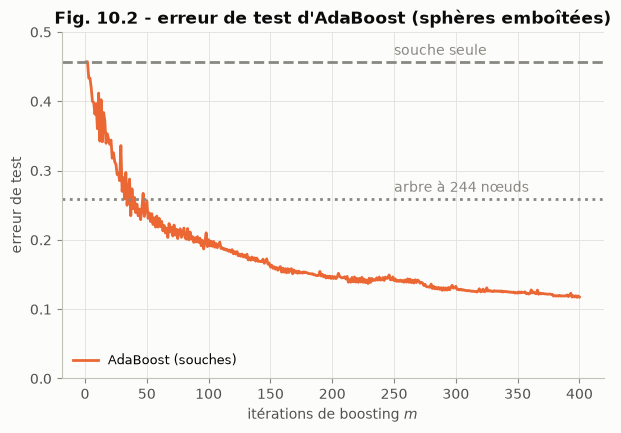

In [6]:
it = np.arange(1, 401)
plt.figure(figsize=(7, 4.5))
plt.plot(it, test_err, color=ORANGE, label="AdaBoost (souches)")
plt.axhline(err_stump, color=GRAY, ls="--")
plt.axhline(err_big, color=GRAY, ls=":")
plt.text(250, err_stump + 0.01, "souche seule", color=GRAY)
plt.text(250, err_big + 0.01, "arbre à 244 nœuds", color=GRAY)
plt.ylim(0, 0.5)
plt.title("Fig. 10.2 - erreur de test d'AdaBoost (sphères emboîtées)")
plt.xlabel("itérations de boosting $m$")
plt.ylabel("erreur de test")
plt.legend()
plt.show()

> **Remarque.** Le livre obtient 5,8 % après 400 itérations ; notre réalisation de la
> simulation donne une erreur un peu plus élevée (de l'ordre de 12 %) mais le
> comportement est le même : le boosting divise l'erreur d'une souche par environ quatre
> et fait nettement mieux qu'un grand arbre. Nous avons vérifié (voir les tests du module)
> que notre implémentation coïncide exactement avec `AdaBoostClassifier` de scikit-learn
> sur ces données ; l'écart vient donc de l'échantillon simulé et de la façon de départager
> les ex æquo, non de l'algorithme.

### Les erreurs pondérées et les coefficients $\alpha_m$

Chaque souche reste faible : son erreur **pondérée** $\mathrm{err}_m$ reste proche de 1/2,
et même s'en rapproche au fil des itérations, car les poids se concentrent sur les cas
difficiles. Les $\alpha_m$ décroissent donc.

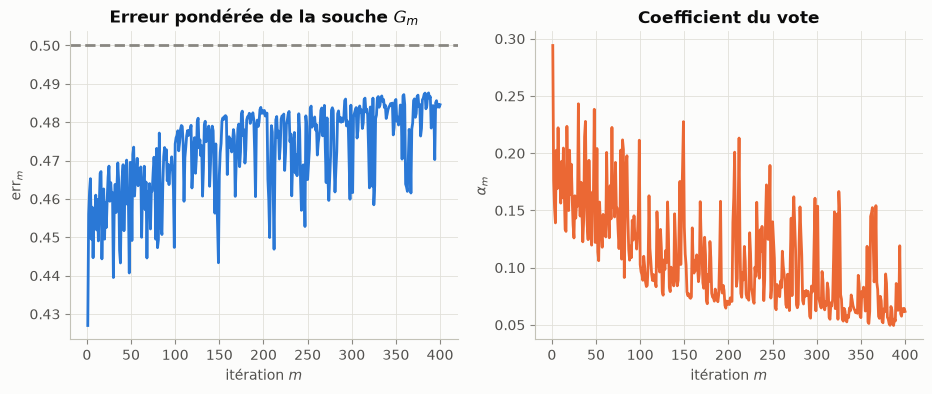

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(it, ada.errs_, color=BLUE)
axes[0].axhline(0.5, color=GRAY, ls="--")
axes[0].set(title="Erreur pondérée de la souche $G_m$", xlabel="itération $m$", ylabel="$\\mathrm{err}_m$")
axes[1].plot(it, ada.alphas_, color=ORANGE)
axes[1].set(title="Coefficient du vote", xlabel="itération $m$", ylabel="$\\alpha_m$")
plt.show()

### Visualiser la repondération en dimension 2

Pour voir les poids « bouger », reprenons la même idée en dimension 2 (un disque :
$Y = 1$ si $X_1^2+X_2^2 > \chi^2_2(0{,}5) = 2\log 2$). La taille de chaque point est
proportionnelle à son poids $w_i$ après $m$ itérations.

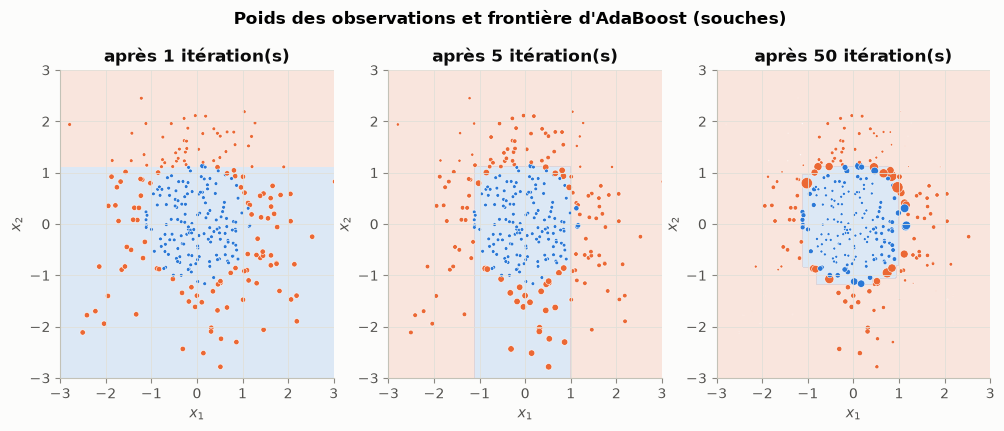

In [8]:
rng2 = np.random.RandomState(1)
X2, y2 = simulate_nested_spheres(300, p=2, rng=rng2)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, m in zip(axes, [1, 5, 50]):
    ab = AdaBoostM1(n_estimators=m).fit(X2, y2)
    # poids après m itérations : on les recalcule à partir des alpha et des souches
    w = np.full(len(y2), 1 / len(y2))
    for a, t in zip(ab.alphas_, ab.trees_):
        w = w * np.exp(a * (t.predict(X2) != y2))
    w /= w.sum()
    xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
    Z = ab.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-2, 0, 2], cmap=TWO_CLASS, alpha=0.15)
    ax.scatter(X2[:, 0], X2[:, 1], s=3000 * w, c=np.where(y2 == 1, ORANGE, BLUE),
               edgecolor="white", linewidth=0.4)
    ax.set(title="après %d itération(s)" % m, xlabel="$x_1$", ylabel="$x_2$",
           xlim=(-3, 3), ylim=(-3, 3))
fig.suptitle("Poids des observations et frontière d'AdaBoost (souches)", fontweight="bold", y=1.03)
plt.show()

Les points proches de la frontière circulaire, difficiles à classer avec des coupures
parallèles aux axes, deviennent de plus en plus lourds ; la frontière, somme de fonctions
en escalier de $x_1$ et de $x_2$, épouse progressivement le cercle.

## 3. Le boosting ajuste un modèle additif

La clé de la réussite d'AdaBoost se lit dans (10.1) : c'est un **développement additif**
sur des fonctions de base élémentaires. Plus généralement, on considère des modèles

$$f(x) = \sum_{m=1}^M \beta_m\, b(x; \gamma_m) \qquad \text{(éq. (10.3))},$$

où les $\beta_m$ sont des coefficients réels et $b(x;\gamma)$ une fonction simple de $x$
paramétrée par $\gamma$ : neurone $\sigma(\gamma_0 + \gamma_1^T x)$ (chapitre 11),
ondelette, fonction spline (MARS), ou **arbre** ($\gamma$ = variables de coupure, seuils
et valeurs des feuilles).

Ajuster un tel modèle revient à minimiser une perte $L$ moyenne :

$$\min_{\{\beta_m,\gamma_m\}_{1}^{M}} \sum_{i=1}^N L\Big(y_i, \sum_{m=1}^M \beta_m b(x_i;\gamma_m)\Big) \qquad \text{(éq. (10.4))}.$$

C'est en général un problème d'optimisation très difficile (non convexe, en grande
dimension). En revanche, ajuster **une seule** fonction de base,
$\min_{\beta,\gamma}\sum_i L(y_i, \beta b(x_i;\gamma))$ (éq. (10.5)), est souvent facile.

### Algorithme 10.2 - modélisation additive pas à pas (*forward stagewise*)

1. Initialiser $f_0(x) = 0$.
2. Pour $m = 1, \dots, M$ :
   1. calculer $\displaystyle (\beta_m, \gamma_m) = \arg\min_{\beta,\gamma}\sum_{i=1}^N L\big(y_i, f_{m-1}(x_i) + \beta\, b(x_i;\gamma)\big)$ ;
   2. poser $f_m(x) = f_{m-1}(x) + \beta_m b(x;\gamma_m)$.

On ajoute les termes un par un, **sans réajuster** ceux déjà présents.

### Cas de la perte quadratique : on ajuste les résidus

Avec $L(y,f) = (y-f)^2$ (éq. (10.6)), on développe :

$$L\big(y_i, f_{m-1}(x_i) + \beta b(x_i;\gamma)\big) = \big(\underbrace{y_i - f_{m-1}(x_i)}_{r_{im}} - \beta b(x_i;\gamma)\big)^2 \qquad \text{(éq. (10.7))}.$$

L'étape 2.1 consiste donc simplement à ajuster la fonction de base aux **résidus**
$r_{im}$ du modèle courant par moindres carrés.

Illustration en dimension 1 : la cible est $\sin(2\pi x)$ bruitée et chaque fonction de base
est une souche de régression. Nous suivons l'algorithme 10.2 à la main.

In [9]:
rng = np.random.RandomState(0)
x1 = np.sort(rng.rand(200))
y1 = np.sin(2 * np.pi * x1) + 0.3 * rng.randn(200)
grid = np.linspace(0, 1, 400)
f_train = np.zeros_like(y1)
f_grid = np.zeros_like(grid)
snapshots = {}
for m in range(1, 101):
    resid = y1 - f_train                       # r_im
    t = RegressionTree(2).fit(x1[:, None], resid)   # souche ajustée aux résidus
    f_train += t.predict(x1[:, None])
    f_grid += t.predict(grid[:, None])
    if m in (1, 3, 10, 100):
        snapshots[m] = f_grid.copy()

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.scatter(x1, y1, s=8, color=GRAY, label="données")
for k, m in enumerate(snapshots):
    plt.step(grid, snapshots[m], where="mid", color=COLORS[k], lw=1.6, label="$f_{%d}$" % m)
plt.plot(grid, np.sin(2 * np.pi * grid), color="black", ls="--", lw=1, label="$\\sin(2\\pi x)$")
plt.title("Modélisation pas à pas avec souches (perte quadratique)")
plt.xlabel("$x$")
plt.ylabel("$f_m(x)$")
plt.legend(ncol=2)
plt.show()

Chaque nouvelle souche corrige l'erreur restante ; après 100 étapes la somme de souches
approche la fonction cible par une fonction en escalier.

> **Remarque.** La perte quadratique n'est pas adaptée à la classification (elle pénalise
> aussi les marges très positives, voir le cours 2). Il faut donc d'autres pertes.